In [1]:

import numpy as np
import pandas as pd
import os
import rioxarray as rxr
from osgeo import gdal
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline, make_pipeline
import geopandas as gpd
import rasterio
from shapely.geometry import box
from shapely.geometry import Point
from rasterio.sample import sample_gen
import xgboost as xgb

from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from skopt import BayesSearchCV
from skopt.space import Integer, Real

c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\cupy\_environment.py:215: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


In [2]:
def save_img(output_filename, reference_filename, array):
    
    reference = gdal.Open(reference_filename)
    
    # 获取地理变换参数和坐标系
    geo_transform = reference.GetGeoTransform()
    projection = reference.GetProjection()

    # 获取矩阵尺寸
    rows, cols = array.shape

    # 创建新的 TIFF 数据集
    driver = gdal.GetDriverByName('GTiff')
    out_data = driver.Create(output_filename, cols, rows, 1, gdal.GDT_Float32)

    # 设置地理变换和坐标系
    out_data.SetGeoTransform(geo_transform)
    out_data.SetProjection(projection)
    

    # 写入数据
    out_data.GetRasterBand(1).WriteArray(array)

    # 保存并关闭文件
    out_data.FlushCache()
    out_data = None
    
def load_refer_icesat_point(FB_raster, icesat_csv_path, output_point, output_raw_point):
    
    df = pd.read_csv(icesat_csv_path)
    lon, lat = 'mean_lon', 'mean_lat'
    LULC_path = "E:/Downloads/tes/UK_LULC.tif"
    geometry = [Point(xy) for xy in zip(df[lon], df[lat])]
    gdf = gpd.GeoDataFrame(df, geometry=geometry)
    gdf.set_crs(epsg=4326, inplace=True)
    points = gdf
    
    with rasterio.open(FB_raster) as src:
        
        if points.crs != src.crs:
            points = points.to_crs(src.crs)
        coords = [(point.x, point.y) for point in points.geometry]
        values = list(src.sample(coords))
        
        band_count = src.count
        for band in range(band_count):
            points[f"b{band+1}_FB6"] = [v[band] for v in values]
            
    # with rasterio.open(LULC_path) as src:

    #     if points.crs != src.crs:
    #         points = points.to_crs(src.crs)
    #     coords = [(point.x, point.y) for point in points.geometry]
    #     values = list(src.sample(coords))

    #     band_count = src.count
    #     points['LULC'] = [v[0] for v in values] 
     
    icesat_mask = (points['OH'] < 5) & (points['b7_FB6'] > 0) #& ((points['LULC'] == 200) | (points['LULC'] == 80))
    data = points[icesat_mask]
    
    points.to_file(output_raw_point)
    data.to_file(output_point)
    
    return data

def optimize_random_forest(x_train, y_train,  n_iter=30, cv=3):

    # if feature_columns is None:
    #     raise ValueError("feature_columns must be provided.")

    classifier = RandomForestRegressor(random_state=42)

    search_space = {
        'n_estimators': Integer(50, 500),
        'max_depth': Integer(3, 20),
        'min_samples_split': Integer(2, 20),
        'min_samples_leaf': Integer(1, 20),
        'max_features': Real(0.1, 1.0)
    }

    opt = BayesSearchCV(
        estimator=classifier,
        search_spaces=search_space,
        n_iter=n_iter,
        cv=cv,
        scoring='neg_mean_squared_error',
        random_state=42,
        n_jobs=-1
    )

    opt.fit(x_train, y_train)

    best_params = opt.best_params_
    print('Best hyperparameters:', best_params)
    print('Best score (negative MSE):', opt.best_score_)

    # 使用最优参数重新训练模型
    final_model = RandomForestRegressor(**best_params, random_state=42)
    # final_model.fit(x_train, y_train)

    return best_params, final_model


In [4]:
year = 2019
year_list = [2019, 2020, 2021, 2022, 2023, 2024]
ICESat_points_list = []
for year in year_list:
    ICESat_path = f'G:\ICESat-2\Region1_map\Region1a_map\A{year}\A_Region1a_30m_{year}_new10.shp' 
    ICESat_path_ = f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10.shp'
    k = gpd.read_file(ICESat_path)
    # k2 = gpd.read_file(ICESat_path_)
    ICESat_points_list.append(k.to_crs(epsg=4326))
    # ICESat_points_list.append(k2.to_crs(epsg=4326))
data = pd.concat(ICESat_points_list)
len(data)

2538

'Region2'

In [19]:
#----------------------------all ICESat-2 used to train RF modal -----------------------------------------
# Base info

region = 'Region6'
location_list = ['Region6d']
year_list = [2019, 2020, 2021, 2022, 2023, 2024]
method = 'RF'
band = 4

join_info = ['Region5', 'Region5f']
join_info1 = ['Region6', 'Region6e']
join_info2 = ['Region6', 'Region6a']


for i in range(len(location_list)):
    
    location = location_list[i]
    
    LULC_path = "E:/Downloads/tes/UK_LULC.tif"
    LULC = rxr.open_rasterio(LULC_path, masked=True).squeeze()
    target_band, target_id = ['b1_FB6','b2_FB6','b3_FB6','b4_FB6'], [0, 1, 2, 3]
    #target_band, target_id = ['b1_FB6'], [0]
    
    # load classifer  
    #---------------------------------------------------------
    # ICESat_points_list = []
    # for k in range(len(year_list)):
        
    #     FB_raster_path_ = f"G:\ICESat-2\{region}_map\{location}_map\A{year_list[k]}/{location}_{year_list[k]}_FB6_new9.tif"
        
    #     ICESAT_csv_path_ = f'G:\ICESat-2\{region}\{region}_{location}\A_{location}_30m_{year_list[k]}_new10.csv'
    #     output_raw_point = f'G:\ICESat-2\{region}_map\{location}_map\A{year_list[k]}\A_{location}_30m_{year_list[k]}_raw_new10.shp'
    #     output_point = f'G:\ICESat-2\{region}_map\{location}_map\A{year_list[k]}\A_{location}_30m_{year_list[k]}_new10.shp'
    #     data = load_refer_icesat_point(FB_raster_path_, ICESAT_csv_path_, output_point, output_raw_point)
            
    #     ICESat_points_list.append(data.to_crs(epsg=4326))
    
    year_list = [2019, 2020, 2021, 2022, 2023, 2024]
    ICESat_points_list = []
    for year in year_list:
        ICESat_path = f'G:\ICESat-2\{join_info[0]}_map\{join_info[1]}_map\A{year}\A_{join_info[1]}_30m_{year}_new10.shp' 
        ICESat_path__ = f'G:\ICESat-2\{join_info1[0]}_map\{join_info1[1]}_map\A{year}\A_{join_info1[1]}_30m_{year}_new10.shp' 
        ICESat_path___ = f'G:\ICESat-2\{join_info2[0]}_map\{join_info2[1]}_map\A{year}\A_{join_info2[1]}_30m_{year}_new10.shp' 
        ICESat_path_ = f'G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_new10.shp'
        k = gpd.read_file(ICESat_path)
        k2 = gpd.read_file(ICESat_path_)
        k3 = gpd.read_file(ICESat_path__)
        k4 = gpd.read_file(ICESat_path___)
        ICESat_points_list.append(k.to_crs(epsg=4326))
        ICESat_points_list.append(k2.to_crs(epsg=4326))
        ICESat_points_list.append(k3.to_crs(epsg=4326))
        ICESat_points_list.append(k4.to_crs(epsg=4326))

    #---------------------------------------------------------
    
    data = pd.concat(ICESat_points_list)
    y_train = data['OH'].values
    x_train = data[target_band].values
    
    if method == 'RF':
        best_params, classifier = optimize_random_forest(x_train, y_train)
        classifier.fit(x_train, y_train)
    elif method == 'Linear':
        classifier = np.polyfit(x_train[:, 0], y_train, deg=1)
    else:
        classifier = np.polyfit(x_train[:, 0], y_train, deg=2)
    
    for j in range(len(year_list)):
      
        # Input info 
        FB_raster_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year_list[j]}/{location}_{year_list[j]}_FB6_new9.tif"
    
        # Output Info
        output_path = f'G:\ICESat-2\{region}_map\{location}_map\A{year_list[j]}\{location}_{year_list[j]}_{band}_{method}_FB6_new9_bys_join.tif'


        if not os.path.exists(FB_raster_path):
            print(FB_raster_path, ' is not exist!')
            break
       

        # Elevation mapping
        raster = rxr.open_rasterio(FB_raster_path).values
        raster = np.nan_to_num(raster, nan = 0)
        selected_raster = raster[target_id, :, :]

        if len(selected_raster.shape) != 3:
            row, col = selected_raster.shape
            selected_raster = selected_raster.reshape(1, row, col)
        else: 
            bands, row, col = selected_raster.shape

        print('selected_raster.shape', selected_raster.shape)

        k = 0
        result = np.array([[]])
        for i in range(row):
            
            x_train = np.transpose(selected_raster[:, i, :])
            if method == 'RF':
                y_pred = classifier.predict(x_train)
            elif method == 'Linear':
                y_pred = np.polyval(classifier, x_train)
            else:
                y_pred = np.polyval(classifier, x_train)
            
            result = np.append(result, y_pred)
            
            if i%(int(row/5)) == 0:
                
                print(k*20 , '%_ is done')
                k = k+1
        
        result = result.reshape(row, col)
        print(result.shape, type(result))
        # tf_mask = raster[6,:,:].flatten()
        # result[tf_mask == 0] = 0
        # result_ = result.reshape(row, col)
        tf_mask = raster[6,:,:]#.flatten()
        # Freq_s2 = raster[5,:,:]#.flatten()
        
        z = rxr.open_rasterio(FB_raster_path, masked=True).squeeze() 
        LULC_aligned = LULC.rio.reproject_match(z)
        
        #result[(tf_mask == 0) | ((LULC_aligned != 200) & (LULC_aligned != 80))] = 0
        result[(tf_mask == 0)] = 0       

        save_img(output_path, FB_raster_path, result)
        print(f'{location}_{year_list[j]} is output to {output_path}')

Best hyperparameters: OrderedDict([('max_depth', 6), ('max_features', 0.4371553329590512), ('min_samples_leaf', 2), ('min_samples_split', 14), ('n_estimators', 94)])
Best score (negative MSE): -1.0109383490278536
selected_raster.shape (4, 1307, 1759)
0 %_ is done
20 %_ is done
40 %_ is done
60 %_ is done
80 %_ is done
100 %_ is done
(1307, 1759) <class 'numpy.ndarray'>
Region6d_2019 is output to G:\ICESat-2\Region6_map\Region6d_map\A2019\Region6d_2019_4_RF_FB6_new9_bys_join.tif
selected_raster.shape (4, 1307, 1759)
0 %_ is done
20 %_ is done
40 %_ is done
60 %_ is done
80 %_ is done
100 %_ is done
(1307, 1759) <class 'numpy.ndarray'>
Region6d_2020 is output to G:\ICESat-2\Region6_map\Region6d_map\A2020\Region6d_2020_4_RF_FB6_new9_bys_join.tif
selected_raster.shape (4, 1307, 1759)
0 %_ is done
20 %_ is done
40 %_ is done
60 %_ is done
80 %_ is done
100 %_ is done
(1307, 1759) <class 'numpy.ndarray'>
Region6d_2021 is output to G:\ICESat-2\Region6_map\Region6d_map\A2021\Region6d_2021_4_RF

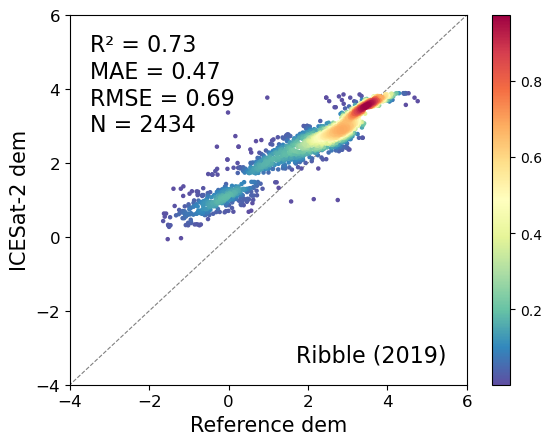

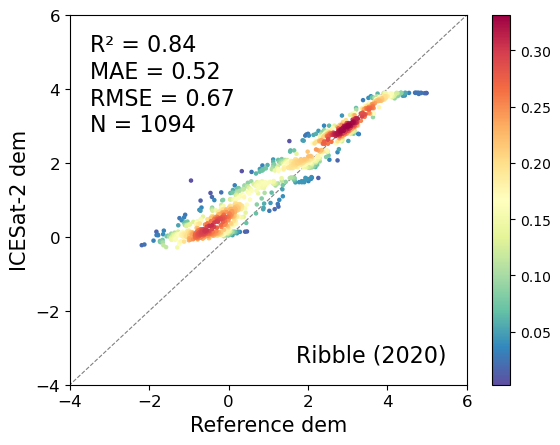

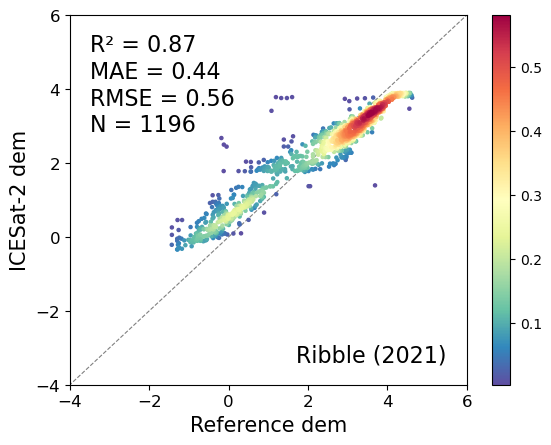

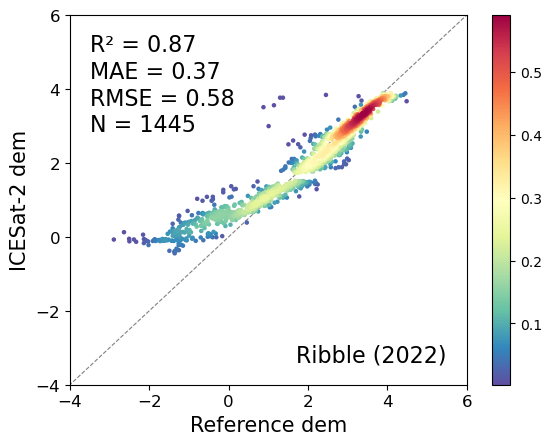

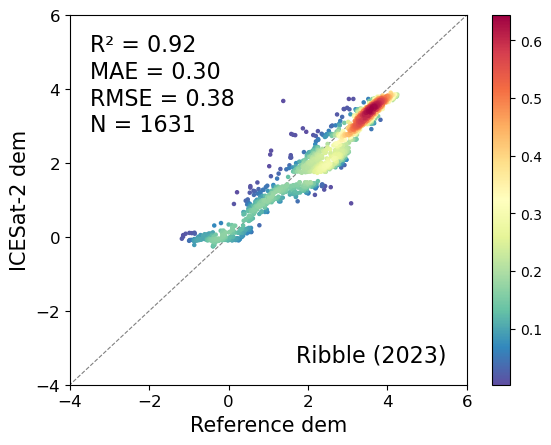

In [21]:
import rasterio
import geopandas as gpd
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import calculate_default_transform, reproject
from rasterio.transform import from_origin
import numpy as np
import geopandas as gpd
from shapely.geometry import Point
from shapely.geometry import box
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from scipy.stats import pearsonr
from sklearn.metrics import r2_score
import pandas as pd
import numpy as np
import rioxarray as rxr

region = 'Region4'
location = 'Ribble'
location2 = 'Ribble'

year_list = [2019, 2020, 2021, 2022, 2023]
# year_list = [2019]

#-------------------- For ICESat-2 Validation-----------------------

for j in range(len(year_list)):
# 路径  
    year = year_list[j]
    #shp_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_new10_final.shp"
    shp_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_new10.shp"
    output_shp_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_new10_valid.shp"
    # output_shp_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_new10_valid_kk.shp"
    output_csv_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_new10.csv"
    raster_path = f"G:\DTM_ref\{location2}\{location2}_{year}\{location2}_masked_{year}.tif"
    retrieved_DEM_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\{location}_{year}_4_RF_FB6_new9_bys_join.tif"

        # 1. 读取 shp 点数据
    points = gpd.read_file(shp_path)

    # 2. 打开栅格数据
    with rasterio.open(raster_path) as src:
        raster_crs = src.crs  # 获取 raster 的坐标系
            
            # 3. 如果坐标系不同，则重投影点数据
        if points.crs != raster_crs:
        # print(f"坐标系不一致，正在从 {points.crs} 转换为 {raster_crs}")
            points = points.to_crs(raster_crs)

        # 4. 获取坐标并提取像元值（默认波段 1）
        coords = [(geom.x, geom.y) for geom in points.geometry]
        values = [val[0] for val in src.sample(coords)]
    points['Ref_dem'] = values
    with rasterio.open(retrieved_DEM_path) as src:
        raster_crs = src.crs  # 获取 raster 的坐标系
            
            # 3. 如果坐标系不同，则重投影点数据
        if points.crs != raster_crs:
        # print(f"坐标系不一致，正在从 {points.crs} 转换为 {raster_crs}")
            points = points.to_crs(raster_crs)

        # 4. 获取坐标并提取像元值（默认波段 1）
        coords = [(geom.x, geom.y) for geom in points.geometry]
        values_dem = [val[0] for val in src.sample(coords)]

        # 5. 将像元值添加到 GeoDataFrame 中
    points['Re_dem'] = values_dem
    
        # 6. 保存结果
    # points.to_file(output_shp_path)
    # points[['geometry', 'raster_val', 'OH']].to_csv(output_csv_path, index=False)
    z = points[['geometry', 'Ref_dem', 'OH', 'Re_dem']]
    z = z[z!=-999]
    z = z[z!=6]
    z = z[z!=0]
    z = z.dropna()

    # x = np.array(z['raster_val'])
    # y = np.array(z['OH'])


    #     #R, _ = pearsonr(y, x)
    # R = r2_score(y, x)
    # MAD = np.mean(np.abs(y-x))
    # MSB = np.mean((y-x))
    # RMSE = np.sqrt(np.mean((y-x)**2))
    # num = int(len(x))
    
    x = np.array(z['Ref_dem'])  # 参考值 / 真值
    y = np.array(z['Re_dem'])          # 预测值

    # 以 x 为真实值，y 为预测值进行评价
    R = r2_score(x, y)  # R²
    MAD = np.mean(np.abs(x - y))  # Mean Absolute Deviation
    MSB = np.mean(x - y)          # Mean Signed Bias
    RMSE = np.sqrt(np.mean((x - y)**2))  # Root Mean Squared Error
    num = len(x)
        

    xy = np.vstack([x,y])  #  将两个维度的数据叠加
    z = gaussian_kde(xy)(xy)  # 建立概率密度分布，并计算每个样本点的概率密度

    # Sort the points by density, so that the densest points are plotted last
    idx = z.argsort()
    x, y, z = x[idx], y[idx], z[idx]

    fig, ax = plt.subplots()
    textstr = f"R² = {R:.2f}\nMAE = {MAD:.2f}\nRMSE = {RMSE:.2f} \nN = {num}"
    name = f'{location2} ({year})'
    ax.text(0.05, 0.95, textstr, transform = ax.transAxes, fontsize = 16, verticalalignment = 'top')
    ax.text(0.95, 0.05, name, transform=ax.transAxes, fontsize=16, verticalalignment='bottom', horizontalalignment='right')

    ax.set_xlabel('Reference dem', fontsize = 15)
    ax.set_ylabel('ICESat-2 dem', fontsize = 15)
    ax.plot([-6, 6], [-6, 6], color='gray', linestyle='--', linewidth=0.8, zorder=1)
    sc = plt.scatter(x, y, c=z, s=5, cmap='Spectral_r', zorder=2)
    cbar = plt.colorbar(sc)

        # plt.scatter(x, y,c=z, s=2,cmap='Spectral_r') # c表示标记的颜色
        # plt.colorbar()

    ax.set_xlim(-4, 6)
    ax.set_ylim(-4, 6)
    ax.set_yticks(np.arange(-4, 6.1, 2))
    ax.tick_params(axis='both', labelsize=12)
    plt.show()
